
# Laboratorium 1: Poznaj swoje dane


W ramach naszych zajęć będziemy przechodzić przez kolejne warstwy systemu NLP:

`dane → baseline → reprezentacja → transformer → IE/NER → LLM → retrieval → RAG → ewaluacja`

Ten sam sposób myślenia będzie wracał na każdych zajęciach:

1. **pytanie badawcze,**
2. **hipoteza,**
3. **eksperyment,**
4. **metryka,**
5. **analiza błędów,**
6. **wniosek.**


> **Pytanie badawcze na dziś:** zanim wybierzemy model, czy wiemy, na jakich danych będziemy go trenować i testować?




## Po tych zajęciach student potrafi:

- wykonać podstawowy EDA dla danych tekstowych;
- sprawdzić rozkład klas i długości tekstów;
- wykryć puste rekordy, duplikaty (i potencjalne duplikaty);
- sprawdzić, czy między `train`, `validation` i `test` nie ma wycieku danych (data leakage);
- zbudować powtarzalny split i zapisać jego manifest;
- przygotować prostą kartę opisową zbioru;
- odróżnić problem modelu od problemu danych.

### Zasada na dziś

> **Podejrzanie dobry wynik jest powodem do szczegółowej ewaluacji, nie do świętowania.**



## Dane: PolEmo 2.0 / KLEJ

Pracujemy na polskich recenzjach konsumenckich z zadania [PolEmo 2.0](https://huggingface.co/datasets/allegro/klej-polemo2-in) w benchmarku KLEJ.

Klasy sentymentu:

- `plus`: pozytywny,
- `minus`: negatywny,
- `zero`: neutralny,
- `amb`: niejednoznaczny.

Repozytorium danych:  
https://huggingface.co/datasets/allegro/klej-polemo2-in

Publikacja KLEJ:  
https://arxiv.org/abs/2005.00630

Licencja zbioru na Hugging Face: CC BY-SA 4.0.

> **Ważne:** w projekcie produkcyjnym sprawdzamy nie tylko jakość danych, ale również ich pochodzenie, licencję, warunki redystrybucji i możliwość przetwarzania.



## Ustawienia wstępne

Do laboratorium wystarczy klasyczny stack Data Science.

Jeśli pracują Państwo w izolowanym / nowym środowisku:

```bash
pip install pandas numpy matplotlib scikit-learn pyarrow
```

In [42]:

from pathlib import Path
import hashlib
import json
import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

RANDOM_STATE = 42

pd.set_option("display.max_colwidth", 160)
pd.set_option("display.max_columns", 50)

ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)



## 1. Pobranie danych

Ładujemy oficjalne splity. Podział danych jest częścią eksperymentu, a nie technicznym szczegółem.


In [43]:
# TODO: ładowanie splitów datasetu (pliki train.csv, valid.csv, test.csv w repozytorium HF)
#
# Po tej komórce MUSZĄ istnieć (używają ich dalsze komórki):
#   URLS        - dict: split -> URL pliku
#   splits      - dict: "train" / "validation" / "test" -> DataFrame z kolumnami text, target, split
#   train_df, val_df, test_df
#   SPLIT_SIZES - dict: split -> liczba rekordów
#   CLASSES     - lista klas
#   LABEL_MAP   - dict: oryginalna etykieta -> plus / minus / zero / amb

# Uwaga: nazwy kolumn w pliku źródłowym mogą różnić się od nazw używanych w notatniku.

BASE_URL = "https://huggingface.co/datasets/allegro/klej-polemo2-in/resolve/main"

URLS = {
    "train": f"{BASE_URL}/train.csv",
    "validation": f"{BASE_URL}/valid.csv",
    "test": f"{BASE_URL}/test.csv",
}

LABEL_MAP = {
    "__label__meta_plus_m": "plus",
    "__label__meta_minus_m": "minus",
    "__label__meta_zero": "zero",
    "__label__meta_amb": "amb",
}

CLASSES = ["plus", "minus", "zero", "amb"]

splits = {}
for split, url in URLS.items():
    df = pd.read_csv(url)
    df = df.rename(columns={"sentence": "text"})
    df["target"] = df["target"].map(LABEL_MAP)
    df["split"] = split
    splits[split] = df[["text", "target", "split"]]

train_df, val_df, test_df = splits["train"], splits["validation"], splits["test"]
SPLIT_SIZES = {split: len(df) for split, df in splits.items()}

SPLIT_SIZES

{'train': 5783, 'validation': 723, 'test': 722}


# Zadanie 1: Sanity check danych

Zanim zrobią Państwo coś bardziej zaawansowanego, proszę odpowiedzieć na pytanie:

1. Jakie kolumny zawiera zbiór?
2. Jaki jest typ każdej kolumny?
3. Czy liczba rekordów zgadza się między źródłem a tym, co faktycznie wczytaliśmy?
4. Czy występują wartości brakujące?
5. Czy etykiety mają ten sam zbiór wartości w każdym splicie? Jeśli nazwy etykiet są nieczytelne, proszę zdefiniować `LABEL_MAP` (np. `__label__meta_plus_m` → `plus`) i zapisać go w manifeście.
6. Czy są rekordy z pustym albo bardzo krótkim tekstem?

### Do wykonania

Proszę uzupełnić komórkę poniżej. Wynik powinien zawierać jedną małą tabelę ewaluacyjną per split.


In [44]:
# TODO: sanity check dla train / validation / test.
#
# Minimalne kolumny tabeli:
# - split
# - rows
# - columns
# - missing_text
# - missing_target
# - unique_labels
#
# Wskazówka:
# display(df.isna().sum())
# display(df["target"].value_counts(dropna=False))

audit_rows = []

for split, df in splits.items():
  columns_info = df.dtypes.astype(str).to_dict()

  audit_rows.append({
      "split": split,
      "rows": df.shape[0],
      "columns": columns_info,
      "missing_text": df["text"].isna().sum(),
      "missing_target": df["target"].isna().sum(),
      "unique_labels": df["target"].value_counts(dropna=False).to_dict(),
  })

pd.DataFrame(audit_rows)

,split,rows,columns,missing_text,missing_target,unique_labels
0,train,5783,"{'text': 'str', 'target': 'str', 'split': 'str'}",0,0,"{'minus': 2194, 'plus': 1568, 'amb': 1050, 'zero': 971}"
1,validation,723,"{'text': 'str', 'target': 'str', 'split': 'str'}",0,0,"{'minus': 271, 'plus': 209, 'zero': 127, 'amb': 116}"
2,test,722,"{'text': 'str', 'target': 'str', 'split': 'str'}",0,0,"{'minus': 300, 'plus': 197, 'zero': 117, 'amb': 108}"


In [45]:
shortest_lengths = {
    split: df["text"].str.len().nsmallest(5).tolist()
    for split, df in splits.items()
}

pd.DataFrame(shortest_lengths)

,train,validation,test
0,1,211,29
1,47,218,51
2,78,222,189
3,113,226,207
4,148,232,208


> 1. Jakie kolumny zawiera zbiór? <br>
> Zbiór zawiera kolumny: "text", "target" i "split".

> 2. Jaki jest typ każdej kolumny? <br>
> kolumna "text" - String; kolumna "target" - String; kolumns "split" - String;

> 3. Czy liczba rekordów zgadza się między źródłem a tym, co faktycznie wczytaliśmy? <br>
> Tak, zgadza się.

> 4. Czy występują wartości brakujące? <br>
> Nie, wartości brakujące nie występują.

> 5. Czy etykiety mają ten sam zbiór wartości w każdym splicie? <br>
> Tak, każdly split zawiera wartości ze zbioru {minus, plus, zero, amb}.

> 6. Czy są rekordy z pustym albo bardzo krótkim tekstem? <br>
> Nie ma rekordów z pustym tekstem, ale są takie z bardzo krótkim (długość 1).


## Hipoteza 1

Czy dane są zbalansowane?

Zanim sporządzą Państwo wykres, proszę sformułować hipotezę.

> Spodziewam się, że minus będzie klasą dominującą, ponieważ ludzie zwykle piszą swoją opinię jeśli mają negatywne odczucia odnośnie czegoś.


# Zadanie 2: Rozkład klas

Proszę policzyć:

- liczebność klas,
- udział procentowy klas,
- rozkład osobno dla `train`, `validation`, `test`.

Następnie proszę odpowiedzieć:

1. Czy accuracy będzie wystarczającą metryką na późniejszych zajęciach?
2. Jaki wynik osiągnąłby naiwny klasyfikator zawsze wybierający najczęstszą klasę?
3. Czy rozkłady klas między splitami są podobne?


In [46]:

# TODO: tabela rozkładu klas dla każdego splitu

class_tables = []

for split, df in splits.items():
    print(f"===== {split} =====")
    class_audit = []
    
    class_count = df["target"].value_counts(dropna=False).to_dict()
    class_percentage = df["target"].value_counts(dropna=False, normalize=True).to_dict()

    for clazz in CLASSES:
        class_audit.append({
            "class": clazz,
            "count": class_count[clazz],
            "percentage (%)": round(class_percentage[clazz] * 100, 2)
        })

    split_table = pd.DataFrame(class_audit)
    display(split_table)
    class_tables.append(split_table.assign(split=split))

class_dist = pd.concat(class_tables, ignore_index=True)

===== train =====


,class,count,percentage (%)
0,plus,1568,27.11
1,minus,2194,37.94
2,zero,971,16.79
3,amb,1050,18.16


===== validation =====


,class,count,percentage (%)
0,plus,209,28.91
1,minus,271,37.48
2,zero,127,17.57
3,amb,116,16.04


===== test =====


,class,count,percentage (%)
0,plus,197,27.29
1,minus,300,41.55
2,zero,117,16.20
3,amb,108,14.96


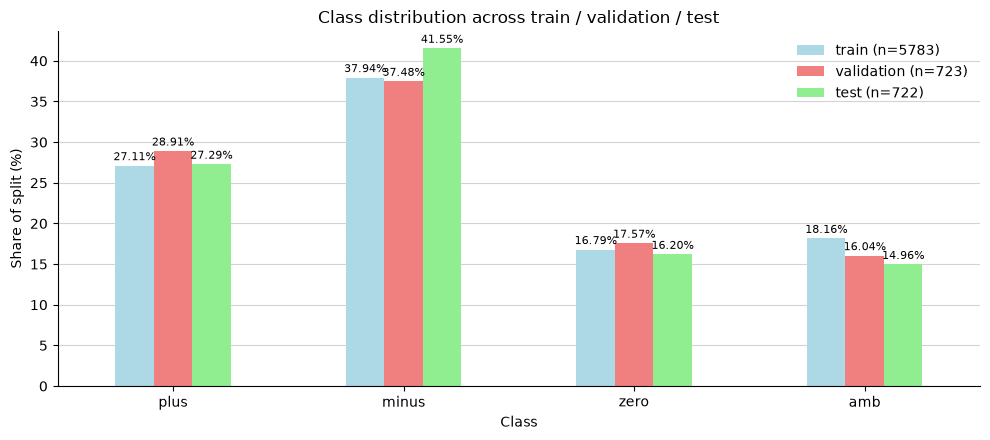

In [47]:

# TODO: wykres rozkładu klas

SPLIT_COLORS = {"train": "lightblue", "validation": "lightcoral", "test": "lightgreen"}

pct = class_dist.pivot(index="class", columns="split", values="percentage (%)").loc[CLASSES, list(splits)]

ax = pct.plot.bar(figsize=(10, 4.5), color=SPLIT_COLORS, rot=0)

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f%%", fontsize=8, padding=2)

ax.set_xlabel("Class")
ax.set_ylabel("Share of split (%)")
ax.set_title("Class distribution across train / validation / test")
ax.legend([f"{s} (n={SPLIT_SIZES[s]})" for s in pct.columns], frameon=False)
ax.grid(axis="y", color="lightgray", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

> 1. Czy accuracy będzie wystarczającą metryką na późniejszych zajęciach? <br>
> Nie, mamy tu przypadek z niezbalansowaniem klas, więc metryka accuracy nie będzie wystarczająca.

> 2. Jaki wynik osiągnąłby naiwny klasyfikator zawsze wybierający najczęstszą klasę? <br>
> W tym wypadku klasyfikator ten wybierał by klasę "minus" i osiągnął by wynik w okolicach 40% accuracy.

> 3. Czy rozkłady klas między splitami są podobne? <br>
> Tak, różnice są w granicach paru punktów procentowych.


# Zadanie 3: Jak wygląda „typowy tekst”?

Długość tekstu jest jednym z pierwszych parametrów, które warto sprawdzić.

Dp wyświetlania tekstu proszę dodać cechy:

- `n_chars`: liczba znaków,
- `n_words`: liczba słów (regex `\w+`) oraz `n_words_split` (`split()` po białych znakach),
- `n_lines`: liczba linii.

Proszę policzyć co najmniej:

- minimum,
- medianę,
- średnią,
- 90. percentyl,
- 95. percentyl,
- 99. percentyl,
- maksimum.

Następnie proszę obejrzeć (i zanotować wnioski z obserwacji):

- 5 najkrótszych tekstów,
- 5 najdłuższych tekstów.

### Pytania

- Czy ekstremalnie długi dokument zawsze jest błędem?
- Co długość dokumentów może później zmienić w tokenizacji, batchowaniu i chunkingu?
- Dlaczego `n_words_split` ≠ `n_words`? Co to mówi o przygotowaniu tekstów w tym zbiorze i jak może wpłynąć na tokenizatory w kolejnych labach?

In [48]:
all_df = pd.concat(splits.values(), ignore_index=True)

# TODO: do dodania n_chars, n_words, n_words_split, n_lines.

all_df["n_chars"] = all_df["text"].str.len()
all_df["n_words"] = all_df["text"].str.count(r"\w+")
all_df["n_words_split"] = all_df["text"].str.split().str.len()
all_df["n_lines"] = all_df["text"].str.split(r"\r?\n").str.len().fillna(0).astype(int)

with pd.option_context("display.max_colwidth", None):
    display(all_df.head())


,text,target,split,n_chars,n_words,n_words_split,n_lines
0,"Super lekarz i człowiek przez duże C . Bardzo duże doświadczenie i trafne diagnozy . Wielka cierpliwość do ludzi starszych . Od lat opiekuje się moją Mamą staruszką , i twierdzę , że mamy duże szczęście , że mamy takiego lekarza . Naprawdę nie wiem cobyśmy zrobili , gdyby nie Pan doktor . Dzięki temu , moja mama żyje . Każda wizyta u specjalisty jest u niego konsultowana i uważam , że jest lepszy od każdego z nich . Mamy do Niego prawie nieograniczone zaufanie . Można wiele dobrego o Panu doktorze jeszcze napisać . Niestety , ma bardzo dużo pacjentów , jest przepracowany ( z tego powodu nawet obawiam się o jego zdrowie ) i dostęp do niego jest trudny , ale zawsze możliwy .",plus,train,681,121,126,1
1,"Bardzo olewcze podejscie do pacjenta . Przyprowadzajac dziecko z ostra wysypka na calym ciele trwajaca od 2 tygodni Pani doktor stwierdzila ze nie widzi wskazan wystawienia dziecku skierowania na testy skorne . Chocby na nasza prosbe i dodam iz w prywatnej klinice ( gdzie tak czy siak musielibysmy za to zaplacic ) Odmowila rowniez wystawienia zaswiadczenia o tym ze dziecko jest "" zdrowe "" i moze uczeszczac do przedszkola twierdzac ze takich zaswiadczen sie nie wystawia . L4 oczywiscie rozniez nie wchodzilo w gre , . Jednym slowem z gabinetu wyszlismy bez niczego mimo iz kierowani bylismy przez dwoch innych pediatrow na natychmiastowe testy do alergologa .",minus,train,663,97,107,1
2,"Lekarz zalecił mi kurację alternatywną do dotychczasowej , więc jeszcze nie daję najwyższej oceny ( zobaczymy na ile okaże się skuteczna ) . Do Pana doktora nie mam zastrzeżeń : bardzo profesjonalny i kulturalny . Jedyny minus dotyczy gabinetu , który nie jest nowoczesny , co może zniechęcać pacjentki .",amb,train,304,48,50,1
3,""" Konsumenci oczywiście kierują się ceną . Te leki są tańsze , ale dzisiaj nie możemy już powiedzieć , że znacznie tańsze . Jest to mniej krępujące , nie trzeba wychodzić z domu , nie trzeba udawać się do lekarza czy prosić o receptę . W takich przypadkach kupujący nie kieruje się zdrowym rozsądkiem , ale ceną - naiwnie szukając leków z niesprawdzonych źródeł . Podrobione leki mogą być skażone , zanieczyszczone lub zawierać substancje toksyczne czy w ogóle nieodpowiedni skład . Często mają też składniki nieaktywne - w żaden sposób nie wpływające na poprawę bądź ( powodujące ) pogorszenie stanu zdrowia "" - wyjaśniła ekspertka . Dodała także , że "" podróbki "" mogą mieć również składniki aktywne w nieodpowiednich dawkach , zbyt silne czy zmieszane w sposób nieodpowiedni , a badania pokazują , że w podrobionych lekach znajdują się trucizny dla szczurów , wosk do podłogi , cement , gips i podobne substancje .",zero,train,917,158,156,1
4,"Pani Doktor Iwona jest profesjonalistką w każdym calu : ) Idąc do stomatologa zawsze czuję przeraźliwy strach . Pani Doktor Iwona jest wyrozumiała i delikatna , bardzo miła , cierpliwie wyjaśnia każdy zaistniały problem a co najbardziej mi się podoba to fakt , że w swoim działaniu jest bardzo stanowcza i konkretna . Dla mnie to jasny znak , że specjalista który się mną zajmuje , doskonale wie co i jak robi . Pozwala mi to poczuć się bezpiecznie . Wiem , że jestem w dobrych rękach . A do tego uśmiech i ciepło . . . . . po strachu ani śladu . Pani Iwono DZIĘKUJĘ : D",plus,train,570,103,109,1


In [49]:
# TODO: tabela statystyk długości

LENGTH_COLS = ["n_chars", "n_words", "n_words_split", "n_lines"]

length_stats = {
    "min": all_df[LENGTH_COLS].min(),
    "median": all_df[LENGTH_COLS].median(),
    "mean": all_df[LENGTH_COLS].mean(),
    "p90": all_df[LENGTH_COLS].quantile(0.90),
    "p95": all_df[LENGTH_COLS].quantile(0.95),
    "p99": all_df[LENGTH_COLS].quantile(0.99),
    "max": all_df[LENGTH_COLS].max(),
}

length_stats_df = pd.DataFrame(length_stats).round(1)
display(length_stats_df)
display(all_df.groupby("split")["n_chars"].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).loc[list(splits)].round(1))

,min,median,mean,p90,p95,p99,max
n_chars,1,696.0,777.0,1294.0,1605.6,2335.2,5391
n_words,1,121.0,135.2,227.0,286.6,420.5,920
n_words_split,1,121.0,136.3,228.0,288.6,414.7,987
n_lines,1,1.0,1.0,1.0,1.0,1.0,1


,count,mean,std,min,50%,90%,95%,99%,max
split,,,,,,,,,
train,5783.0,780.6,433.1,1.0,698.0,1298.0,1628.8,2343.3,5391.0
validation,723.0,769.4,424.6,211.0,702.0,1284.4,1570.0,2267.6,3917.0
test,722.0,756.2,404.4,29.0,684.5,1260.8,1561.4,2198.7,2567.0


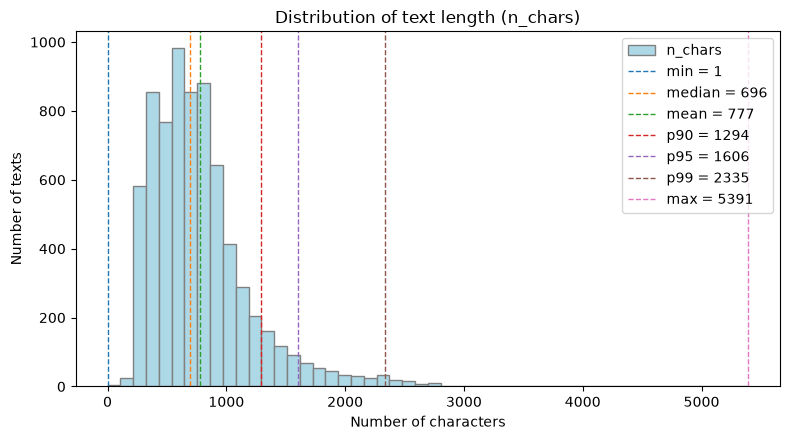

In [50]:
# TODO: histogram długości tekstów

all_df["n_chars"].plot.hist(bins=50, figsize=(8, 4.5), color="lightblue", edgecolor="gray")

for i, (stat, value) in enumerate(length_stats_df.loc["n_chars"].items()):
    plt.axvline(value, color=f"C{i}", linestyle="--", linewidth=1, label=f"{stat} = {value:.0f}")

plt.xlabel("Number of characters")
plt.ylabel("Number of texts")
plt.title("Distribution of text length (n_chars)")
plt.legend()
plt.tight_layout()
plt.show()

In [51]:
# TODO: skrajne obserwacje

EXTREME_COLS = ["text", "target", "split", "n_chars", "n_words", "n_words_split", "n_lines"]

with pd.option_context("display.max_colwidth", None):
    print("===== 5 najkrótszych tekstów =====")
    display(all_df.nsmallest(5, "n_chars")[EXTREME_COLS])

    print("===== 5 najdłuższych tekstów =====")
    display(all_df.nlargest(5, "n_chars")[EXTREME_COLS])

===== 5 najkrótszych tekstów =====


,text,target,split,n_chars,n_words,n_words_split,n_lines
4476,P,amb,train,1,1,1,1
7041,Marka Baccarat Hotels & Res o,zero,test,29,5,6,1
4310,"Hotel , jak za tą kwotę ( 230 - 2 osoby & aut o",minus,train,47,10,14,1
7095,W grudniu czterogwiazdkowy Hotel Korona Spa & Wel l,zero,test,51,8,9,1
4538,Hotel powinien nazywać się MARNIOR ( z uwagi na kiepska jakosc uslug ) & Gwa r,minus,train,78,13,16,1


===== 5 najdłuższych tekstów =====


text  \
3200  Wybór sylwestrowego pakietu w tym hotelu za gigantyczne pieniądze ( jak na zaproponowane warunki i " atrakcje " ) to jeden z naszych największych błędów . Kierowali śmy się reklamami , ogłoszeniami i wizerunkiem hotelu , który kreuje się na mega luksusowy . . . Po 4 godzinach podróży z dzieckiem i kotem otrzymali śmy kartę do pokoju hotelowego . . . Kiedy do niego weszli śmy z wrażenia opadła m na łóżko , zaścielone pomiętą , wygniecioną pościelą . W pokoju . . . brud . Wykładzina poplamiona , w pokoju jedno okno , balkonowe , nieszczelne , problem z otwarciem ( jak wywietrzyć pokój , z jednym balkonowym oknem , którego nie można uchylić , kiedy przyjeżdża się z kotem ? ) na szybach skraplająca się woda , firanki pogniecione , pozaciągane , niedoprane . Stolik nocny z zepsutą szufladą . Abażury lampek mocno po przejściach , ściany obrzydliwie brudne , zaplamione , brak klimatyzacji . No i wisienka na torcie - łazienka . Oj . . . na grzejniku służącym do suszenia ręczników gruba warstwa kurzu , prysznic . . . . z zasilikonowanym grzybem . Myślę , że żaden cukiernik nie powstydził by się takich umiejętności zdobienia tortów jakie posiada osoba , która silikonowała prysznic na kilka godzin przed naszym przyjściem ( charakterystyczny zapach ) , bateria łazienkowa kwalifikująca się jedynie do wymiany . Oświetlenie w łazience tragiczne , zrobienie makijażu w takim świetle , tylko przy doświetlaniu latarką z telefonu . Tyle o pokoju - pani " kierownik " czy też " menadżer " nawet nie broniła się , bo i jak ? Skoro miała ten brud przed własnymi oczyma ? Zmieniono nam pokój . Czekali śmy na niego prawie 2 godziny . W tym czasie nikt nie zaproponował nam zejścia do restauracji na kawę , poszli śmy sami . . . Kolejny pokój sprzątany na szybko , nieco czystszy , ale ilość odświeżacza powietrza wywoływała odruch wymiotny . . . Po jakimś czasie okazało się , że termostat przy kaloryferze w pokoju nie działa i kaloryfer na 25m2 grzał całą parą . . . Klimatyzacji również brak . Nie wiem , jak ludzie wytrzymują tam latem , my musieli śmy zamykać kota w transporterze średnio co 2 godziny , żeby otworzyć okno na oścież i wychładzać pokój . W nocy było strasznie . Generalnie pokoje małe , niewygodne , nieergonomicznie urządzone . Jedzenie bardzo słabe . Surówki " z wiadra " , typowa niedorobiona garkuchnia . . . Menu sylwestrowe wołające o pomstę do nieba . Jeśli ktoś skusił się na szumnie nazwane BBQ ribbs , to chyba połamał na nich zęby . Rozreklamowany " spacer " po czerwonym dywanie w błysku fleszy nijak miał się do rzeczywistości , zabrakło fleszy . . . Orkiestra grająca na zabawie sylwestrowej przygotowała dziwny repertuar , a kiedy w przerwie grał didżej i było już grubo po północy ludzie zaczęli się dobrze bawić , znowu weszła orkiestra . Ludzie prosili , żeby już nie grała , żeby został didżej , powiedziano im , że orkiestra musi grać . . . dopiero po interwencji kilku osób w recepcji udało się pozbyć orkiestry . Open bar proponował pięć drinków , a po godzinie 2 w nocy zaczęto ludziom odmawiać ich przygotowywania . Kelnerzy serwowali niewybredne żarty poproszeni o doniesienie wódki na stół . . . Na stołach brakowało napojów gazowanych , trzeba było o nie prosić , a kelnerzy niechętnie je donosili . Zorganizowano zabawę sylwestrową dla dzieci , ale panie animatorki nie panowały nad grupą - dzieci wychodziły z sali gdzie i kiedy chciały , a przecież hotel znajduje się nad jeziorem . . . Obsługa hotelu . . . nikt nic nie wie , wszyscy niedoinformowani . Nikt nie powiedział nam , ze wejściówki do zoo i fokarium są w pokoju , że jeśli chcemy iść to musimy je zabrać , a kiedy przed wyjściem pytali śmy o to w recepcji , powiedziano nam , że wystarczy przy wejściu do zoo powiedzieć , że jesteśmy w hotelu . W kasie zoo jednak nikt nic o tym nie wiedział . . . ehhh . Do tego kelnerzy . . . miała m wrażenie , że przez 3 doby pobytu , od śniadania do godziny 22 , a potem w sylwestra do późnej nocy obsługiwali nas ci sami ludzie . Po r

> **5 najkrótszych tekstów:**
> * Wszystkie są ucięte, a nie po prostu krótkie. Kończą się w połowie słowa, np. "Marka Baccarat Hotels & Res o", "Hotel , jak za tą kwotę ( 230 - 2 osoby & aut o".
> * Etykiety często nie wynikają z treści: "P" ma etykietę amb, a urwane zdanie "Hotel , jak za tą kwotę..." ma minus. 
> * Teksty z etykietą zero ("Marka Baccarat Hotels...", "W grudniu czterogwiazdkowy Hotel Korona Spa...") wyglądają na początki artykułów lub informacji prasowych, a nie na recenzje.

> **5 najdłuższych tekstów:**
> * To kompletne, spójne recenzje hoteli (ok. 3900–5400 znaków), bez śladów sklejenia kilku rekordów ani powtórzeń. Długość nie jest tu błędem.
> * Wszystkie mają etykietę minus. Rozbudowane opisy piszą zwykle osoby rozczarowane: opisują sytuację krok po kroku, żądają zwrotu kosztów, ostrzegają innych. 
> * Widać w nich wstępną tokenizację zbioru: oderwane końcówki ("weszli śmy", "wykupiła m"), wielokropek jako ". . ." i długie serie "! ! ! ! !".

> Czy ekstremalnie długi dokument zawsze jest błędem?
> Nie, długość sama w sobie nie świadczy o błędzie. Niektóre osoby piszą dużo, na przykład kiedy są bardzo zadowoleni albo bardzo rozczarowani. Taki dokument to także wartościowa część danych. Długi dokument może być problemem jeśli na przykład: posiada kilka rekordów sklejonych w jeden albo ma powtórzony fragment lub cały tekst.

> Co długość dokumentów może później zmienić w tokenizacji, batchowaniu i chunkingu?
> Modele mają limit długości wejścia, a słowo zwykle zamienia się w więcej niż jeden token, więc długie teksty mogą przekroczyć ten limit i zostać obcięte. Model straci wtedy część treści. Przy batchowaniu krótsze teksty dopełnia się paddingiem do długości najdłuższego tekstu w batchu, więc jeden bardzo długi dokument marnuje pamięć i czas obliczeń. Długie dokumenty można też dzielić na mniejsze fragmenty - chunking, ale pojedynczy fragment nie zawsze oddaje sens całości, więc potem trzeba połączyć wyniki z fragmentów w jedną odpowiedź dla całego dokumentu.

> Dlaczego `n_words_split` ≠ `n_words`? Co to mówi o przygotowaniu tekstów w tym zbiorze i jak może wpłynąć na tokenizatory w kolejnych labach?
> Obie metody liczą słowa inaczej. split() dzieli tekst tylko po spacjach, więc każdy oddzielony spacjami znak interpunkcyjny, np. kropka czy przecinek, liczy jako osobne słowo. Regex \w+ liczy tylko ciągi liter i cyfr, ale za to rozbija na części np. wyrazy z łącznikiem albo daty. Różnica pokazuje, że teksty w zbiorze były już wcześniej stokenizowane: interpunkcja jest odsunięta spacjami, a niektóre końcówki są oderwane od wyrazów (np. „skusili śmy”). Tokenizatory gotowych modeli uczyły się na zwykłym tekście, więc taki zapis będą dzielić inaczej niż naturalne zdania, co może spowodować pogorszenie wyników.


# Zadanie 4: Szum danych

Tekst naturalny nie jest sterylny.

Proszę sprawdzić, ile rekordów zawiera co najmniej jeden z poniższych elementów:

- URL,
- adres e-mail,
- sekwencję wielu wykrzykników lub znaków zapytania,
- dużo WIELKICH LITER,
- znaki nowej linii,
- tekst krótszy niż 20 znaków.

Proszę nie usuwać ich automatycznie!

> Najpierw wykrywamy zjawisko. Potem decydujemy, czy jest błędem, sygnałem czy częścią danych.

Proszę też sprawdzić, czy którakolwiek flaga szumu jest skorelowana z etykietą. Czy to sygnał, artefakt, czy shortcut?

In [52]:
# TODO: proszę obliczyć poniższe flagi bool
#
# has_url, has_email, has_punct_burst, has_newline, is_very_short, high_uppercase
#
# Proponowany próg high_uppercase: uppercase_ratio > 0.5,
# zaleca się eksperyment z tym progiem.
#
# UWAGA: w tym zbiorze interpunkcja jest oddzielona spacjami (np. "! ! !"),
# więc prosty wzorzec [!?]{2,} jej nie wykryje.

has_url = all_df["text"].str.contains(r"https?://\S+|www\.\S+", regex=True, na=False, case=False)
has_email = all_df["text"].str.contains(r"\S+@\S+\.\S+", regex=True, na=False, case=False)
has_punct_burst = all_df["text"].str.contains(r"[!?](?:\s*[!?])+", regex=True, na=False)
has_newline = all_df["text"].str.contains(r"\n", regex=True, na=False)
is_very_short = all_df["n_chars"] < 20
high_uppercase = all_df["text"].str.count(r"[A-Z]") / all_df["n_chars"] > 0.5

def show_examples(mask, title, n=5):
    print(f"===== {title} (łącznie: {mask.sum()}) =====")
    with pd.option_context("display.max_colwidth", None):
        display(all_df.loc[mask, ["text", "target", "split", "n_chars"]].head(n))

show_examples(has_url, "Teksty z adresem URL")
show_examples(has_email, "Teksty z adresem e-mail")
show_examples(has_punct_burst, "Teksty z serią wykrzykników lub znaków zapytania")
show_examples(has_newline, "Teksty ze znakiem nowej linii")
show_examples(is_very_short, "Teksty krótsze niż 20 znaków")
show_examples(high_uppercase, "Teksty z przewagą wielkich liter")

===== Teksty z adresem URL (łącznie: 9) =====


,text,target,split,n_chars
782,"Dodatkowo w najbliższych latach nadal będzie istnieć możliwość poddawania się kolonoskopii przesiewowej bez zaproszenia ( tzw . system oportunistyczny ) . Mogą się na nią zgłaszać – samodzielnie lub z polecenia lekarza podstawowej opieki zdrowotnej osoby w wieku 50 - 65 lat , nie mające objawów mogących świadczyć o obecności raka jelita grubego , jak krwawienie z przewodu pokarmowego ( krew w kale ) , biegunka lub zaparcia , które wystąpiły w ostatnich kilku miesiącach i nie mają znanej przyczyny , a także chudnięcie czy anemia o niewyjaśnionym podłożu . Prof . Reguła zaznaczył , że osoby z takimi objawami powinny podlegać badaniom diagnostycznym ( w tym kolonoskopii ) , ale finansowanym przez NFZ , a nie w ramach programu profilaktycznego , który finansuje Ministerstwo Zdrowia . Informacje na temat ośrodków , do których można się zgłaszać na kolonoskopię przesiewową znajdują się na stronie internetowej Programu Badań Przesiewowych ( http://pbp.org.pl ) .",zero,train,969
1486,"Informacje , które można znaleźć w internecie : Dr n . med . Bożenie Dołyk Specjalizacja : neurologia dziecięca Inne : certyfikat Międzynarodowego Stowarzyszenia Vojty ( IVG ) z zakresu diagnostyki metodą Vojty z prawem nauczania diagnostyki , certyfikat IVG z zakresu terapii Vojty . Komentarz z forum BabyBoom z lipca 2005 : "" Wszystkim matkom które chcą mieć NAPRAWDĘ ZDROWE DZIECKO polecamy Panią doktor Bożenę Dołyk - fachowe podejście i wogóle rewelacja . "" ( http://www.babyboom.pl/forum/zlota-lista-f51/czarna-lista-1846/index6.html#post_message_82728 )",plus,train,561
1525,"Zorganizowano ją w ramach obchodów Polskiego Dnia Spirometrii , który przypada 27 czerwca . Z tej okazji w ponad 150 placówkach medycznych w całym kraju będzie można bezpłatnie wykonać spirometrię . Więcej informacji na ten temat można znaleźć na stronie Polskiej Federacji Stowarzyszeń Chorych na Astmę i POChP , które jest inicjatorem akcji badań ( http://www.astma-alergia-pochp.pl ) . Jak przypomniał prezes Federacji dr Piotr Dąbrowiecki , spirometria pozwala wykryć obturację , czyli zwężenie oskrzeli . „ Na schorzenia , którym towarzyszy obturacja cierpi w Polsce ok . 6 mln chorych – w tym 4 mln na astmę , a 2 mln na przewlekłą obturacyjną chorobę płuc ( POChP ) ” – podkreślił . Dodał , że u połowy z nich ( w tym u 2 mln z astmą i co najmniej 1 mln z POChP ) schorzenie nie jest jeszcze rozpoznane i prawidłowo leczone .",zero,train,832
1557,"Udary mózgu zajmują trzecie miejsce wśród przyczyn zgonów i są głównym powodem niesprawności osób po 40 . roku życia . Rocznie rejestruje się w Polsce 60 - 70 tys . udarów - 30 proc . z nich prowadzi do zgonu w ciągu pierwszego roku . Po pół roku od wystąpienia udaru niedowład połowiczy występuje u połowy pacjentów . Wśród osób , które przeżyły udar około 70 proc . pozostaje niepełnosprawnymi , przy czym 50 proc . wymaga pomocy i opieki innych osób z powodu upośledzonej sprawności fizycznej i psychicznej . 29 października obchodzony jest Światowy Dzień Udaru Mózgu . 4 proste kroki , które mogą uratować życie promuje stowarzysznie "" Udarowcy - liczy się wsparcie "" ( www.udarowcy.com.pl . ) Jeśli podejrzewamy u kogoś udar , wystarczy poprosić , aby się uśmiechnął , powiedział proste zdanie i uniósł ramiona . Udar nie pozwala się uśmiechnąć - po stronie porażonej opada kącik ust . Mówienie najprostszych zdań i rozumienie mowy są utrudnione , a unoszenie ramion jest niemożliwe lub możliwe w ograniczonym zakresie . Jeśli wystąpi którykolwiek z tych objawów , trzeba niezwłocznie zadzwonić pod numer pogotowia ratunkowego .",zero,train,1133
2083,"Tak czy inaczej genetyczne pasożyty robią w naszym genomie niezły bałagan . "" Aż 17 proc . DNA w ludzkim genomie to elementy LINE - 1 kodujące tzw . retrotranspozony "" – powiedział . Jego zespół złożony z młodych naukowców , dr . Zbigniewa Warkockiego - pierwszego autora publikacji , dr . Pawła Krawczyka i Doroty Adamskiej opublikował właśnie w prestiżowym piśmie "" Cell 

===== Teksty z adresem e-mail (łącznie: 0) =====


,text,target,split,n_chars


===== Teksty z serią wykrzykników lub znaków zapytania (łącznie: 808) =====


...

,text,target,split,n_chars


===== Teksty krótsze niż 20 znaków (łącznie: 1) =====


,text,target,split,n_chars
4476,P,amb,train,1


===== Teksty z przewagą wielkich liter (łącznie: 10) =====


,text,target,split,n_chars
86,"JESTEM ZAWIEDZIONA PODEJŚCIEM DOKTORA DO PACJENTÓW , W MOIM PRZYPADKU BYŁO TAK , DZIECKO MA CZESTO POWRACAJĄCY KASZEL , WIĘC WYBRAŁA M SIĘ DO PANA DOKTORA NA TESTY BO CHCIAŁA M WIEDZIEĆ SKĄD TEN KASZEL , WYNIKI WYSZŁY UJEMNE , ŻADNEJ ALERGII , PO PÓŁ ROKU KASZEL NIE USTĄPIŁ , NA DODATEK DOSTAŁ WYSYPKI , UCZULIŁ GO JAKIS PRODUKT , W SZPITALU ZROBILI MU TESTY I OKAZAŁO SIE ŻE MA JEDNAK ALERGIE . PAN DOKTOR BYŁ BARDZO ZAWIEDZIONY , ŻE STRACIŁ CZAS NA MOJEGO SYNKA . BYŁA M W SZOKU , JAK MOŻNA MIEĆ TAKIE PODEJŚCIE DO DZIECKA , CZY MA ALERGIE CZY NIE POWINIEN BYĆ POTRAKTOWANY JAK KAŻDY PACJENT WYMAGAJĄCY POMOCY LEKARZA . NIE POLECAM . JEST WIELE INNYM ALERGOLOGÓW .",minus,train,667
243,"DROGIE PANIE POLECAM ! ! ! ! ! ! DR . ISMAEIL SALLOUM JEST LEKARZEM GODNYM ZAUFANIA . POTRAFI ROZMAWIAC Z PACJETKA TAK ZEBY BYLO DLA NIEJ WSZYSTKO ZROZUMIALE.JA CHODZE OD KILKUNASTU LAT DO DOKTORA KTURY JAKO JEDYNY DAL MI NADZIEJE I WYLECZYL MNIE - - - BEZ OPERACJI - - - MIALAM OGROMNEGO ( wielkosci pomaranczy ) TORBIELA NA JAJNIKU I Z CZYM SIE WIAZALO TO PRZEWLEKLE ZAPALENIE PRZYDATKOW ( niesamowicie bolesne ) A ZOSTALA TYLKO BLIZNA , . WIELU INNYCH LEKARZY KIEROWALI MNIE NA OPERACJE I MOWILI ZE NA TO LEKU NIE MA . DOKTOR SALLOUM POTRAFIL ZAJAC SIE MNA PROFESJONALNIE I WYLECZYL.OD 10 LAT NIE MAM PROBLEMOW . Z PODZIEKOWANIAMI DLA PANA DOKTORA - STALA PACJETKA",plus,train,667
546,"PRACUJE NA BANACHA , RZADKO WIDZIANY PRZY "" ZWYKłYM "" PACJENCIE - CZASEM PRZY "" SWOICH "" . W PRYWATNYM GABINECIE CAłA śCIANA OPRAWIONYCH W RAMKI DYPLOMóW , PO PIERWSZYM BADANIU ZAPOWIEDź KONIECZNYCH KILKU OPERACJI W PRYWATNEJ OCZYWIśCIE KLINICE . POMIMO POSIADANYCH "" śWIEżYCH "" WYMIKóW BADAń OTRZYMAł EM SZEREG SKIEROWAń NA TE SAME - JESZCZE śWIEżSZE - WRAZ Z POLECENIEM ZAPRZYJAźNIONYCH PRZYCHODNI , W KTóRYCH POWINNY BYć WYKONANE . GDY WKRóTCE PO JEDYNEJ WIZYCIE W GABINECIE PRYWATNYM PANA DOKTORA DOSTAł EM SIę NA ODDZIAł NA BANACHA , NIE POZNAł . . . NIEDOSTęPNY , TRUDNO "" WYCIąGNąć "" INFORMACJE O SWOIM ZDROWIU , WYNIKACH BADAń , PLANOWANYCH DZIAłANIACH . POZA TYM WSZYSTKIM - CENIONY W śRODOWISKU AUTORYTET . DLA BOGATYCH PACJENTóW , NIE DLA "" ZWYKłYCH "" LUDZI .",minus,train,770
1877,"ODRADZAM ! ! ! POMIMO ŻE LEKARZ MAJĄCY OSIĄGNIĘCIA ALE NIESTETY BARDZO INTERESOWNY i TRAKTUJĄCY CHOREGO NIE JAK CZŁOWIEKA TYLKO KOLEJNY EKSPERYMENT W SWOJEJ KARIERZE ZAWODOWEJ . PODEJŚCIE POTRAFI "" PAN PROFESOR "" ZMIENIĆ GDY PACJENT ZAPŁACI I TO SŁONO ZA DODATKOWE "" KONSULTACJE MEDYCZNE "" KTÓRE TRWAJĄ "" DOPÓKI KURA ZNOSI ZŁOTE JAJKA """,minus,train,336
2440,"DZIEN DOBRY MAM PYTANIE TROSZKE Z INNEJ BECZKI ! REGULARNIE CWICZE NA SILOWNI , POSTANOWILEM ZACZAC BRAC KREATYNE CZY TO COS SZKODZI LUB PRZESZKADZA W PLODNOSCI BADZ W ZAPLODNIENIU KOBIETY ? ? ? MOJA ZONA MI ODRADZA BO BOI SIE ZE PRZEZ TO NIE ZAJDZIE W CIAZE ALE TO PRZECIEZ NIE JEST ZADEN STERYD TYLKO NATURALNA ODZYWKA PROSZE I DZIEKUJE Z GORY ZA ODPOWIEDZ ! ! ! !",zero,train,366


In [72]:
flags = pd.DataFrame({
    "has_url": has_url,
    "has_email": has_email,
    "has_punct_burst": has_punct_burst,
    "has_newline": has_newline,
    "is_very_short": is_very_short,
    "high_uppercase": high_uppercase,
})

any_flag = flags.any(axis=1)
print(f"Rekordy z co najmniej jedną flagą: {any_flag.sum()} / {len(all_df)} ({any_flag.mean():.1%})")
display(flags.sum().rename("count").to_frame())

overall = all_df["target"].value_counts(normalize=True).rename("cały zbiór")
per_flag = {
    name: all_df.loc[mask, "target"].value_counts(normalize=True)
    for name, mask in flags.items() if mask.any()
}
label_by_flag = pd.concat([overall, pd.DataFrame(per_flag)], axis=1).loc[CLASSES] * 100

display(label_by_flag.round(1).style.format("{:.1f}%", na_rep="—"))

Rekordy z co najmniej jedną flagą: 823 / 7228 (11.4%)


,count
has_url,9
has_email,0
has_punct_burst,808
has_newline,0
is_very_short,1
high_uppercase,10


,cały zbiór,has_url,has_punct_burst,is_very_short,high_uppercase
target,,,,,
plus,27.3%,11.1%,20.7%,—,30.0%
minus,38.3%,11.1%,67.0%,—,50.0%
zero,16.8%,77.8%,1.5%,—,10.0%
amb,17.6%,—,10.9%,100.0%,10.0%


> Co najmniej jedną flagę ma 823 z 7228 rekordów (~11%), prawie wyłącznie z powodu serii !/? (808). E-maili i nowych linii nie ma, a URL i teksty z przewagą wielkich liter są pojedyncze (9 i 10). Seria !/? jest skorelowana z etykietą: 67% takich tekstów to minus, a zero tylko 1%. To raczej prawdziwy sygnał emocji niż artefakt, ale model może się nauczyć skrótu „dużo wykrzykników - minus”.


# Zadanie 5: Duplikaty

Duplikat w danych treningowych nie zawsze jest problemem. Jednak duplikat między zbiorami train i test może zafałszować wyniki.

Zaczniemy od dwóch wersji tekstu:

1. `text_raw`: oryginał,
2. `text_norm`: wersja używana wyłącznie do oceny duplikatów.

Normalizacja:

- Unicode NFKC,
- lowercase,
- redukcja białych znaków,
- trim.

> Nie usuwamy interpunkcji i nie robimy agresywnego preprocessingu.


In [53]:
# TODO:
# preprocessing

def normalize_text(text):
    text = unicodedata.normalize("NFKC", text)  # ujednolicenie znaków Unicode
    text = text.lower()                         # małe litery
    text = re.sub(r"\s+", " ", text)            # wiele białych znaków -> jedna spacja
    return text.strip()                         # usunięcie spacji z początku i końca

all_df["text_raw"] = all_df["text"]
all_df["text_norm"] = all_df["text_raw"].apply(normalize_text)

# TODO:
# 1. jakie dokładne duplikaty text_raw,
# 2. jakie duplikaty text_norm,
# 3. 10 przykładowych grup duplikatów,
# 4. czy ten sam text_norm występuje w więcej niż jednym splicie?

raw_dups = all_df[all_df["text_raw"].duplicated(keep=False)]
print("Rekordy z duplikatem text_raw:", len(raw_dups))

norm_dups = all_df[all_df["text_norm"].duplicated(keep=False)]
print("Rekordy z duplikatem text_norm:", len(norm_dups))

def summarize_groups(df):
    return (
        df.groupby("text_norm")
        .agg(count=("split", "size"), splits=("split", list), labels=("target", list))
        .reset_index()
    )

print("===== 10 przykładowych grup duplikatów =====")
with pd.option_context("display.max_colwidth", None):
    display(summarize_groups(norm_dups).head(10))

splits_per_text = all_df.groupby("text_norm")["split"].nunique()
cross_split_texts = splits_per_text[splits_per_text > 1].index

print(f"===== Teksty w więcej niż jednym splicie: {len(cross_split_texts)} =====")
with pd.option_context("display.max_colwidth", None):
    display(summarize_groups(all_df[all_df["text_norm"].isin(cross_split_texts)]))

Rekordy z duplikatem text_raw: 0
Rekordy z duplikatem text_norm: 0
===== 10 przykładowych grup duplikatów =====


,text_norm,count,splits,labels


===== Teksty w więcej niż jednym splicie: 0 =====


,text_norm,count,splits,labels



## Funkcja `audit_split_leakage`

Proszę napisać funkcję:

```python
audit_split_leakage(df, text_col="text_norm", split_col="split")
```

która zwróci rekordy występujące w więcej niż jednym splicie.

W wyniku chcemy co najmniej:

- tekst / fingerprint,
- liczbę wystąpień,
- listę splitów,
- etykiety.

To będzie pierwszy element naszej semestralnej biblioteki ewaluacyjnej.

In [54]:
def audit_split_leakage(df, text_col="text_norm", split_col="split"):
    splits_per_text = df.groupby(text_col)[split_col].nunique()
    cross_split_texts = splits_per_text[splits_per_text > 1].index

    leakage_df = (
        df[df[text_col].isin(cross_split_texts)]
        .groupby(text_col)
        .agg(
            n_occurrences=(split_col, "size"),
            n_splits=(split_col, "nunique"),
            splits=(split_col, list),
            targets=("target", list),
        )
        .reset_index()
    )

    return leakage_df.sort_values(["n_splits", "n_occurrences"], ascending=False)


leakage = audit_split_leakage(all_df)
display(leakage.head(10))

,text_norm,n_occurrences,n_splits,splits,targets


> Nie ma ani jednego dokładnego duplikatu, ani dla text_raw, ani po normalizacji, ani między splitami.


# Zadanie 6: Prawie duplikaty

Exact match nie wystarczy.

Przykład:

- `Świetny hotel. Polecam!`
- `Świetny hotel - polecam!!!`

Dla człowieka to prawie ten sam tekst. Hash ich nie połączy.

Na próbce danych proszę zbudować prosty detektor zdań, które są prawie duplikatami:

1. `TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5))`,
2. `NearestNeighbors(metric="cosine")`,
3. dla każdego tekstu proszę znaleźć najbliższego **innego** sąsiada (uwaga: przy `n_neighbors=1` sąsiadem jest zwykle ten sam dokument, więc pobierz kilku i pomiń siebie),
4. proszę policzyć podobieństwo jako `1 - cosine_distance`,
5. proszę policzyć pary z podobieństwem np. `>= 0.90`, osobno w obrębie jednego splitu i między splitami.

### Nie chodzi o idealny deduplikator

Celem jest zobaczenie, że decyzja "duplikat / nie duplikat" sama może być problemem modelowym.

In [55]:
# TODO nearest_other_neighbour

def nearest_other_neighbor(X):
    vectorizer = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5))
    nbrs = NearestNeighbors(metric='cosine', n_neighbors=4)

    X_vectorized = vectorizer.fit_transform(X)
    nbrs.fit(X_vectorized)

    distances, indices = nbrs.kneighbors(X_vectorized)

    j = np.zeros(len(indices), dtype=int)
    sim = np.zeros(len(indices))

    for row in range(len(indices)):
        for idx, dist in zip(indices[row], distances[row]):
            if idx != row:
                j[row] = idx
                sim[row] = 1 - dist
                break

    return j, sim


def near_duplicate_pairs(texts):
    j, sim = nearest_other_neighbor(texts)
    pairs = pd.DataFrame({"i": np.arange(len(texts)), "j": j, "sim": sim})

    pairs[["i", "j"]] = np.sort(pairs[["i", "j"]].values, axis=1)
    return pairs.drop_duplicates(subset=["i", "j"]).reset_index(drop=True)


SIM_THRESHOLD = 0.90

pairs = near_duplicate_pairs(all_df["text_norm"])

pairs["cross_split"] = all_df["split"].values[pairs["i"]] != all_df["split"].values[pairs["j"]]

near_dups = pairs[pairs["sim"] >= SIM_THRESHOLD].sort_values("sim", ascending=False)

print(f"Pary z podobieństwem >= {SIM_THRESHOLD}: {len(near_dups)}")
print(f"w obrębie jednego splitu: {(~near_dups['cross_split']).sum()}")
print(f"między splitami: {near_dups['cross_split'].sum()}\n")

print("===== Przykładowe pary =====")
a = all_df.loc[near_dups["i"], ["split", "target", "text"]].reset_index(drop=True).add_suffix("_a")
b = all_df.loc[near_dups["j"], ["split", "target", "text"]].reset_index(drop=True).add_suffix("_b")
example_pairs = pd.concat([near_dups["sim"].round(3).reset_index(drop=True), a, b], axis=1)

with pd.option_context("display.max_colwidth", None):
    display(example_pairs)

Pary z podobieństwem >= 0.9: 3
w obrębie jednego splitu: 2
między splitami: 1

===== Przykładowe pary =====


,sim,split_a,target_a,text_a,split_b,target_b,text_b
0,1.000,train,zero,"„ Przetestowali śmy nasze podłoża na trzech gatunkach bakterii wywołujących zapalenie opon mózgowych : Neisseria meningitidis , Streptococcus pneumoniae i Haemophilus influenzae . Poprawnie wykrywali śmy ich obecność w 95 proc . przypadków , a gatunek identyfikowali śmy z pewnością sięgającą 98 proc . A ponieważ mówimy o niezwykle czułej spektroskopii ramanowskiej , do otrzymania tak precyzyjnych wyników wystarczało nam znalezienie jednej komórki bakteryjnej ” - podkreśla dr Kamińska . Cały przebieg analizy jest w znacznym stopniu zautomatyzowany i do minimum ogranicza kontakt laboranta z badaną próbką . W celu przeprowadzenia pomiaru należy jedynie pobrać pod wyciągiem laminarnym mikrolitrową porcję płynu mózgowo - rdzeniowego do strzykawki , a następnie tę umieścić w pompie strzykawkowej podłączonej do spektrometru Ramana . W celu zwiększenia pewności pomiaru zarejestrowane sygnały są przetwarzane przez oprogramowanie korzystające z zaawansowanych metod statystycznych i obsługującemu pozostaje jedynie odczytać wynik .",test,zero,"„ Przetestowali śmy nasze podłoża na trzech gatunkach bakterii wywołujących zapalenie opon mózgowych : Neisseria meningitidis , Streptococcus pneumoniae i Haemophilus influenzae . Poprawnie wykrywali śmy ich obecność w 95 proc . przypadków , a gatunek identyfikowali śmy z pewnością sięgającą 98 proc . A ponieważ mówimy o niezwykle czułej spektroskopii ramanowskiej , do otrzymania tak precyzyjnych wyników wystarczało nam znalezienie jednej komórki bakteryjnej ! ” - podkreśla dr Kamińska . Cały przebieg analizy jest w znacznym stopniu zautomatyzowany i do minimum ogranicza kontakt laboranta z badaną próbką . W celu przeprowadzenia pomiaru należy jedynie pobrać pod wyciągiem laminarnym mikrolitrową porcję płynu mózgowo - rdzeniowego do strzykawki , a następnie tę umieścić w pompie strzykawkowej podłączonej do spektrometru Ramana . W celu zwiększenia pewności pomiaru zarejestrowane sygnały są przetwarzane przez oprogramowanie korzystające z zaawansowanych metod statystycznych i obsługującemu pozostaje jedynie odczytać wynik ."
1,0.963,train,zero,"Powyższe jest spisem zadań , jakie na co dzień wykonują poza swoimi podstawowymi obowiązkami związanymi z obsługą gości w recepcji - recepcjoniści niejednego małego 3 - gwiazdkowego hotelu „ gdzieś w Polsce ” . Czy 1 . 400 złotych „ na rękę ” z godzinami nocnymi i pracą w niedziele - za wykonywanie wszystkich powyższych prac to dużo czy mało ? Czy w hotelu 3 - gwazdkowym recepcjoniści w ogóle powinni wykonywać takie prace ? Odpowiedź na te pytania zależy od kilku warunków : jak duży jest hotel 3 - gwiazdkowy tzn . ile ma pokoi i innych stref ; gdzie jest położony , jak wysoka jest frekwencja , jak układa się sezonowość . I w końcu : jak podchodzimy do systemu rozliczania pracownika . 160 pokojowy hotel 3 - gwiazdkowy położony w centrum Warszawy , Wrocławia czy Poznania , w którym ruch gości i klientów trwa praktycznie od godziny 6 . 00 rano do 2 . 00 w nocy , gdzie średnio codziennie wynajęte jest 100 pokoi a w hotelu przebywa 120 - 150 gości - nie sposób porównać do 12 - 20 pokojowego hotelu wypoczynkowego , położonego w głębi województwa warmińsko - mazurskiego lub do miejskiego hotelu w niewielkim mieście powiatowym . Recepcjonista z dużego wielkomiejskiego hotelu a recepcjonista z małego , lokalnego hotelu - to dwóch różnych pracowników .",train,zero,"Powyższe jest spisem zadań , jakie na co dzień wykonują poza swoimi podstawowymi obowiązkami związanymi z obsługą gości w recepcji - recepcjoniści niejednego małego 3 - gwiazdkowego hotelu „ gdzieś w Polsce ” . Czy 1 . 400 złotych „ na rękę ” z godzinami nocnymi i pracą w niedziele - za wykonywanie wszystkich powyższych prac to dużo czy mało ? Czy w hotelu 3 - gwazdkowym recepcjoniści w ogóle powinni wykonywać takie prace ? Odpowiedź na te pytania zależy od kilku warunków : jak duży jest hotel 3 - gwiazdkowy tzn . ile ma pokoi i innych st

> Przy progu 0.90 detektor znajduje tylko 3 pary: 2 w obrębie train i 1 między train a test (podobieństwo 1.0, ucięta kopia tego samego tekstu). Mimo braku dokładnych duplikatów jeden przypadek wycieku między train a test istnieje.


# Zadanie 7: Czy split jest częścią danych?

Proszę porównać:

### A. oficjalny split
`train / validation / test`

### B. naiwny random split
po połączeniu wszystkich rekordów:

```python
train_test_split(..., stratify=target, random_state=42)
```

Nie trenujemy jeszcze modelu docelowego. Chcemy zobaczyć, czy sam sposób dzielenia danych może zmienić eksperyment.

Proszę sprawdzić dla obu wariantów:

- rozkład klas,
- exact duplicates między train/test,
- near-duplicates, jeśli masz czas.

### Pytanie

Czy losowy split jest zawsze metodologicznie poprawny?

Proszę pomyśleć o:

- użytkownikach,
- autorach,
- czasie,
- źródłach,
- dokumentach należących do tej samej sprawy,
- wielu fragmentach pochodzących z jednego dokumentu.


In [ ]:
all_data = [splits["train"], splits["validation"], splits["test"]]
all_data = pd.concat(all_data).reset_index(drop=True)
all_data = all_data.drop(columns=["split"])

naive_rest_df, naive_test_df = train_test_split(all_data, test_size=SPLIT_SIZES["test"], stratify=all_data["target"], random_state=RANDOM_STATE)
naive_train_df, naive_val_df = train_test_split(naive_rest_df, test_size=SPLIT_SIZES["validation"], stratify=naive_rest_df["target"], random_state=RANDOM_STATE)

naive_df = pd.concat([naive_train_df.assign(split="train"), naive_val_df.assign(split="validation"), naive_test_df.assign(split="test")], ignore_index=True)
naive_df["text_norm"] = naive_df["text"].apply(normalize_text)

naive_df.head()

,text,target,split,text_norm
0,"Umawiając kilka miesięcy temu wizyty u Pani Doktor kierowała m się opiniami innych użytkowników portalu ( wówczas wszystkie były pozytywne ) , niestety - w ...",minus,train,"umawiając kilka miesięcy temu wizyty u pani doktor kierowała m się opiniami innych użytkowników portalu ( wówczas wszystkie były pozytywne ) , niestety - w ..."
1,Byli śmy w tej restauracji w 4 osoby więc miała m możliwość popróbować 4 różne dania : ) Żurek bardzo smaczny chociaż preferuję wersję z ziemniakami a nie z...,amb,train,byli śmy w tej restauracji w 4 osoby więc miała m możliwość popróbować 4 różne dania : ) żurek bardzo smaczny chociaż preferuję wersję z ziemniakami a nie z...
2,"Hotel wybrał em ze względu na położenie - blisko do rynku ! Niestety warunki nie najlepsze : pokoj zimny , położony na parterze nad parkingiem podziemnym ta...",minus,train,"hotel wybrał em ze względu na położenie - blisko do rynku ! niestety warunki nie najlepsze : pokoj zimny , położony na parterze nad parkingiem podziemnym ta..."
3,Drodzy Państwo wybrał em się z dziewczyną na majówkę do hotelu Rezydent . Według opinii hotel powinien być w ścisłej czołówce obiektów w trójmieście . Stało...,minus,train,drodzy państwo wybrał em się z dziewczyną na majówkę do hotelu rezydent . według opinii hotel powinien być w ścisłej czołówce obiektów w trójmieście . stało...
4,"Witam , nie moge sie zgodzic z negatywnymi opiniami , była m u doktora dwa razy z dzieckiem najpierw na kontroli , a nastepnie na badaniu USG owszem jest ba...",plus,train,"witam , nie moge sie zgodzic z negatywnymi opiniami , była m u doktora dwa razy z dzieckiem najpierw na kontroli , a nastepnie na badaniu usg owszem jest ba..."


In [57]:
class_pct = pd.crosstab(naive_df["split"], naive_df["target"], normalize="index") * 100
display(class_pct.round(1).loc[list(splits), CLASSES])

target,plus,minus,zero,amb
split,,,,
train,27.3,38.3,16.8,17.6
validation,27.4,38.3,16.7,17.6
test,27.3,38.2,16.9,17.6


In [58]:
naive_leakage = audit_split_leakage(naive_df)
train_test = naive_leakage["splits"].apply(lambda s: "train" in s and "test" in s).sum()

print("===== Dokładne duplikaty między splitami =====")
print(f"Teksty w więcej niż jednym splicie: {len(naive_leakage)}")
print(f"  w tym jednocześnie w train i test: {train_test}\n")


===== Dokładne duplikaty między splitami =====
Teksty w więcej niż jednym splicie: 0
  w tym jednocześnie w train i test: 



In [59]:
j, sim = nearest_other_neighbor(naive_df["text_norm"])
naive_pairs = pd.DataFrame({"i": np.arange(len(naive_df)), "j": j, "sim": sim})

naive_pairs[["i", "j"]] = np.sort(naive_pairs[["i", "j"]].values, axis=1)
naive_pairs = naive_pairs.drop_duplicates(subset=["i", "j"])

split_i = naive_df["split"].values[naive_pairs["i"]]
split_j = naive_df["split"].values[naive_pairs["j"]]
naive_pairs["cross_split"] = split_i != split_j
naive_pairs["train_test"] = ((split_i == "train") & (split_j == "test")) | ((split_i == "test") & (split_j == "train"))

naive_near = naive_pairs[naive_pairs["sim"] >= SIM_THRESHOLD]

print(f"===== Near-duplicates (podobieństwo >= {SIM_THRESHOLD}) =====")
print(f"Pary: {len(naive_near)}")
print(f"w obrębie jednego splitu: {(~naive_near['cross_split']).sum()}")
print(f"między splitami: {naive_near['cross_split'].sum()}")
print(f"w tym między train i test: {naive_near['train_test'].sum()}")

===== Near-duplicates (podobieństwo >= 0.9) =====
Pary: 3
w obrębie jednego splitu: 2
między splitami: 1
w tym między train i test: 0


> Oba podziały dają bardzo podobne rozkłady klas. W losowym splicie para near-duplicate trafiła do train i validation, a w oficjalnym do train i test.

> Czy losowy split jest zawsze metodologicznie poprawny?

> Nie, losowy split nie zawsze jest poprawny. Działa tylko wtedy, gdy rekordy są od siebie niezależne. Ponieważ losowy split nie uwzględnia powiązań między rekordami, może rozmieścić spokrewnione ze sobą dane w różnych podzbiorach, co prowadzi do wycieku informacji, np:
> * Użytkownicy / autorzy: ten sam autor ma swój styl, słownictwo i skłonność do konkretnej oceny. Jeśli jego recenzje trafią do train i do test, model może rozpoznawać autora, a nie sentyment recenzji.
> * Czas: w produkcji model przewiduje przyszłość na podstawie przeszłości. Losowy split pozwala mu podglądać przyszłe dane. 
> * Źródła i dokumenty z tej samej sprawy: teksty z tego samego serwisu lub tej samej sprawy dzielą te same cechy (styl, nazwy, fakty). Jeśli losowy split rozdzieli je między zbiory, model nauczy się konkretnej sprawy/źródła zamiast ogólnego wzorca.
> * Wiele fragmentów z jednego dokumentu: dzielenie ciągłego materiału na małe kawałki powoduje, że sąsiednie fragmenty, które mogą mieć taki sam kontekst, trafiają do róznych splitów.


# Zadanie 8: Eksperyment: wyciek danych potrafi „ulepszyć” model

Teraz użyjemy bardzo prostego klasyfikatora wyłącznie jako sondy diagnostycznej. Nie optymalizujemy hiperparametrów. To będzie temat kolejnego laboratorium.

Pipeline:

`TF-IDF → Logistic Regression`

Najpierw policzymy wynik na poprawnym splicie, a potem celowo zanieczyścimy train przykładami z testu.

### Hipoteza

Proszę sformułować przed uruchomieniem założenie:

> Jak zmieni się accuracy / macro-F1 po wprowadzeniu leakage i dlaczego?


> Spodziewam się, że accuracy oraz macro-F1 wzrosną, ponieważ model będzie mieć w zbiorze testowym dane, na których się uczył także poprawnie je dopasuje.

In [60]:

probe = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_features=50_000,
        sublinear_tf=True,
    )),
    ("clf", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE,
    )),
])

def evaluate_probe(train_part: pd.DataFrame, test_part: pd.DataFrame):
    probe.fit(train_part["text"], train_part["target"])
    pred = probe.predict(test_part["text"])
    return {
        "accuracy": accuracy_score(test_part["target"], pred),
        "macro_f1": f1_score(test_part["target"], pred, average="macro"),
    }
# Wynik bazowy na oficjalnym splicie:
clean_score = evaluate_probe(train_df, test_df)
clean_score


{'accuracy': 0.8365650969529086, 'macro_f1': 0.7965659940906175}

In [61]:
# CELowo tworzymy błędny eksperyment: dokładamy część TESTU do TRAIN.
# Proszę nie robić tego nigdy w prawdziwej ewaluacji!!! :)

def score(model, part):
    pred = model.predict(part["text"])
    return accuracy_score(part["target"], pred), f1_score(part["target"], pred, average="macro")

rows = []
for frac in [0.0, 0.05, 0.10, 0.20, 0.50, 1.0]:
    leaked = test_df.sample(frac=frac, random_state=RANDOM_STATE)
    train_leaky = pd.concat([train_df, leaked], ignore_index=True)
    probe.fit(train_leaky["text"], train_leaky["target"])
    m = test_df.index.isin(leaked.index)
    row = {"leak_fraction": frac}
    row["acc_all"], row["f1_all"] = score(probe, test_df)
    row["acc_leaked"], row["f1_leaked"] = score(probe, test_df[m]) if m.any() else (np.nan, np.nan)
    row["acc_unleaked"], row["f1_unleaked"] = score(probe, test_df[~m]) if (~m).any() else (np.nan, np.nan)
    rows.append(row)

pd.DataFrame(rows)

,leak_fraction,acc_all,f1_all,acc_leaked,f1_leaked,acc_unleaked,f1_unleaked
0,0.00,0.836565,0.796566,NaN,NaN,0.836565,0.796566
1,0.05,0.837950,0.793777,0.916667,0.824472,0.833819,0.791962
2,0.10,0.839335,0.794763,0.944444,0.903195,0.827692,0.784910
3,0.20,0.855956,0.820547,0.951389,0.934320,0.832180,0.792879
4,0.50,0.889197,0.867642,0.955679,0.945997,0.822715,0.791268
5,1.00,0.958449,0.951080,0.958449,0.951080,NaN,NaN



## Analiza

Proszę odpowiedzieć krótko:

1. Jak duża była różnica dla każdej wartości leak_fraction?
2. Czy wynik wzrósł tak mocno, jak było oczekiwane?
3. Dlaczego wyciek przez duplikaty może być bardziej lub mniej szkodliwy zależnie od modelu?
4. Czy wysoki wynik sam w sobie pozwala odróżnić dobry model od błędnej ewaluacji?
5. Jakie testy automatyczne dobrze dodać do pipeline'u danych?
6. Czy wzrost wyniku wynika z zapamiętania wyciekłych rekordów (acc_leaked), czy z poprawy na pozostałych (acc_unleaked)?

> 1. Zmiana metryk względem wartości początkowych (bez wycieku):
>
> | leak_fraction | Δ Accuracy | Δ F1 |
> |---:|---:|---:|
> | 0.05 | +0.14 | −0.28 |
> | 0.10 | +0.28 | −0.18 |
> | 0.20 | +1.94 | +2.40 |
> | 0.50 | +5.26 | +7.11 |
> | 1.00 | +12.19 | +15.45 |

<br>

> 2. Tak, spodziewałem się, że wynik bardzo wzrośnie, jednak zakładałem że przy pełnym wycieku Accuracy i F1 osiągną wynik 100%.

> 3. Wyciek przez duplikaty może być bardziej szkodliwy lub mniej zależnie od tego jak działa nasz model - jeśli mamy doczynienia z modelem o dużej pojemności i bez regularyzacji może on łatwo zapamiętać próbki ze zbioru treningowego, w przypadku modeli posiadających silną regularyzację potrafią one uczyć się bardziej ogólnych wag przez co wyciek mniej na nie wpływa.

> 4. Nie, może być jedynie sugestią do tego aby sprawdzić poprawność procesu przygotowania danych, szczególnie gdy mamy do czynienia z dużym skokiem wyniku między naszym modelem a baseline'nem,

> 5. Testy, które warto dodać to chociażby testy na wykrywanie duplikatów i prawie duplikatów, można dodać także testy sprawdzające czy w danych nie ma żadnych braków, oraz testy sanity do sprawdzania poprawności przekształceń wykonywanych na danych.

> 6. Wzrost wyniku wynika wyłącznie z zapamiętywania wyciekłych rekordów, po acc_unleaked i f1_unleaked widzimy, że model nie uogólnia wcale lepiej, a wręcz gorzej.


# Zadanie 9: Dane do kolejnego laboratorium

Na następnych zajęciach będziemy budować baseline'y klasyfikacyjne. Proszę zatem przygotować czysty, wersjonowany artefakt.

### Minimalna polityka czyszczenia

Rekomendujemy:

- usunąć rekordy bez tekstu lub labelu,
- **nie modyfikować** `validation` i `test` (zachować oficjalne rozmiary); duplikaty w tych splitach tylko oznaczyć flagą,
- z `train` usunąć exact duplicates wewnątrz `train` oraz rekordy, których `text_norm` występuje w `validation` lub `test`,
- nie zmieniać treści tekstu bez uzasadnienia,
- nie usuwać "dziwnych" tekstów tylko dlatego, że wyglądają dziwnie,
- każdą operację zapisać w manifeście wraz z liczbą usuniętych rekordów.

### Do zapisania

```text
artifacts/
├── polemo2_clean.parquet
└── splits.json
```

`splits.json` powinien zawierać co najmniej:

- `random_state`,
- liczebności splitów,
- listę klas,
- datę / wersję źródła lub URL,
- opis wykonanych operacji czyszczenia,
- `label_map`,
- liczebności splitów przed i po czyszczeniu,
- SHA-256 pliku `polemo2_clean.parquet`,
- wersje Pythona, pandas i scikit-learn.

In [62]:
cleaning_log = []
df = all_df[["text", "target", "split", "text_norm"]].copy()

n_before = len(df)
df = df[df["text"].notna() & df["text"].str.strip().ne("") & df["target"].isin(CLASSES)]
cleaning_log.append({"op": "drop_missing_text_or_label", "splits": "all", "removed": n_before - len(df)})

df["dup_within_split"] = df.duplicated(["split", "text_norm"], keep=False)
df["dup_cross_split"] = df.groupby("text_norm")["split"].transform("nunique") > 1
near_cross_idx = near_dups.loc[near_dups["cross_split"], ["i", "j"]].values.ravel()
df["near_dup_cross_split"] = df.index.isin(near_cross_idx)
for flag in ["dup_within_split", "dup_cross_split", "near_dup_cross_split"]:
    cleaning_log.append({"op": f"flag_{flag}", "splits": "all", "flagged": int(df[flag].sum())})

is_train = df["split"].eq("train")
train_dups = is_train & df.duplicated(["split", "text_norm"], keep="first")
df = df[~train_dups]
cleaning_log.append({"op": "drop_exact_dups_within_train", "splits": "train", "removed": int(train_dups.sum())})

is_train = df["split"].eq("train")
eval_texts = set(df.loc[~is_train, "text_norm"])
train_leak = is_train & df["text_norm"].isin(eval_texts)
df = df[~train_leak]
cleaning_log.append({"op": "drop_train_records_in_val_or_test", "splits": "train", "removed": int(train_leak.sum())})

clean_df = df.reset_index(drop=True)

display(pd.DataFrame(cleaning_log))
print({k: int(v) for k, v in clean_df["split"].value_counts().items()})

import sys, sklearn

clean_df.to_parquet(ARTIFACTS / "polemo2_clean.parquet", index=False)

manifest = {
    "random_state": RANDOM_STATE,
    "source": "allegro/klej-polemo2-in",
    "source_urls": URLS,
    "label_map": LABEL_MAP,
    "classes": CLASSES,
    "split_sizes_raw": SPLIT_SIZES,
    "split_sizes_clean": {k: int(v) for k, v in clean_df["split"].value_counts().items()},
    "cleaning": cleaning_log,
    "parquet_sha256": hashlib.sha256((ARTIFACTS / "polemo2_clean.parquet").read_bytes()).hexdigest(),
    "versions": {"python": sys.version.split()[0], "pandas": pd.__version__, "sklearn": sklearn.__version__},
}
(ARTIFACTS / "splits.json").write_text(json.dumps(manifest, indent=2, ensure_ascii=False))

,op,splits,removed,flagged
0,drop_missing_text_or_label,all,0.0,NaN
1,flag_dup_within_split,all,NaN,0.0
2,flag_dup_cross_split,all,NaN,0.0
3,flag_near_dup_cross_split,all,NaN,2.0
4,drop_exact_dups_within_train,train,0.0,NaN
5,drop_train_records_in_val_or_test,train,0.0,NaN


{'train': 5783, 'validation': 723, 'test': 722}


1558

# Zadanie 10: Karta zbioru

Proszę stworzyć plik `dataset_card.md`. Proszę opisać zbiór tak, jakby dane miała przejąć jutro inna osoba w zespole.

Minimalna zawartość:

## Dataset
Nazwa i źródło.

## Task
Co próbujemy przewidywać / analizować?

## Schema
Jakie kolumny mają dane?

## Labels
Jakie są klasy?

## Splits
Jak wykonano podział?

## Data quality
Jakie problemy znaleziono?

## Cleaning
Co zmieniono, a czego świadomie nie zmieniono?

## Leakage audit
Czy znaleziono pokrywające się rekordy między splitami?

## License / provenance
Skąd pochodzą dane i na jakiej licencji są udostępnione? Proszę porównać licencję w metadanych zbioru na Hugging Face z licencją w treści karty zbioru i zdecydować, którą przyjąć (i dlaczego). Proszę też sprawdzić tabelę rozkładu klas w karcie: czy nazwy sentymentu zgadzają się z danymi?

## Limitations
Czego nie wolno wnioskować na podstawie tego zbioru?


# Zacne przypadki porażek

Na każdych laboratoriach będziemy kolekcjonować przypadki, w których dane lub modele zachowują się niezgodnie z naszymi przewidywaniami, zabawnie, niewłaściwie.

Proszę znaleźć 3 takie wpisy we własnych wynikach; chodzi o rekordy, które są problematyczne, zaskakujące albo niejednoznaczne.

Dla każdego zapiszcie:

| id | problem | tekst | dlaczego to ważne? |
|---|---|---|---|
| 1 | bardzo krótki tekst | "P" - amb | Etykieta nie wynika z treści, więc model uczy się szumu. |
| 2 | label wydaje się dyskusyjny | "Lekarz zalecił mi kurację alternatywną do dotychczasowej , więc jeszcze nie daję najwyższej oceny ( zobaczymy na ile okaże się skuteczna ) . Do Pana doktora nie mam zastrzeżeń : bardzo profesjonalny i kulturalny . Jedyny minus dotyczy gabinetu , który nie jest nowoczesny , co może zniechęcać pacjentki ." - amb | Tekst jest raczej pozytywny, a granica `amb`/`plus` jest subiektywna, co obniża wiarygodność metryk. |
| 3 | label wydaje się dyskusyjny i tekst jest urwany | "Hotel , jak za tą kwotę ( 230 - 2 osoby & aut o" - minus | Etykieta nie wynika z treści (tekst urwany), poza tym początek opinii brzmi jakby mogła to być zarówno opinia negatywna jak i pozytywna, także oznaczenie wydaje się być nieprawidłowe. |

Przykładowe problemy:

- label wydaje się dyskusyjny,
- bardzo krótki tekst,
- tekst zawiera kilka sprzecznych ocen,
- zdania duplikaty lub prawie duplikaty,
- nietypowa ortografia,
- ironia,
- tekst spoza oczekiwanej domeny.


# Zadanie 11: Zadanie-Podsumowanie

### A. Group leakage
Proszę zaproponować sytuację, w której teksty nie są identyczne, ale powinny należeć do tego samego splitu.

> Taka sytuacja może wystąpić na przykład przy wielu negatywnych/pozytywnych opiniach tego samego hotelu, model mógłby zacząć przyporządkowywać etykietę na bazie nazwy hotelu zamiast faktycznej opinii. 

### B. Temporal leakage
Załóżmy, że mamy timestampy. Proszę zaprojektować split użyteczny w prawdziwym wdrożeniu: uczymy na przeszłości, testujemy na przyszłości.

> Sortujemy rekordy po timestampie i dzielimy je według progów czasowych, a nie losowo. Najstarsze ~80% trafia do train, kolejne ~10% do validation, a najnowsze ~10% do test. Dzięki temu model uczy się na przeszłości i działa na przyszłych danych.

### C. Fingerprinting
Proszę zapisać SHA-256 znormalizowanego tekstu i przygotować mały manifest umożliwiający sprawdzanie overlapu między kolejnymi wersjami datasetu.

In [63]:
def fingerprint(text):
    return hashlib.sha256(normalize_text(text).encode("utf-8")).hexdigest()

clean_df["sha256"] = clean_df["text"].apply(fingerprint)

fp_manifest = {
    "fingerprints": clean_df.groupby("split")["sha256"].apply(list).to_dict(),
}

(ARTIFACTS/"fingerprints_manifest.json").write_text(json.dumps(fp_manifest, indent=2))

534965

### D. Near-duplicate benchmark
Proszę ręcznie ocenić 50 par wygenerowanych przez stworzony przez siebie detektor jako `duplicate / not_duplicate` i sprawdzić precision dla kilku progów podobieństwa. Pary należy losować z całego zakresu `sim ∈ [0.7, 1.0]` (np. po 10 z pięciu przedziałów), inaczej nie da się policzyć precision dla niższych progów. Proszę raportować `n` w każdym przedziale.

> Uwaga: to nie jest wyścig o najdłuższy kod. Najlepsze rozwiązanie to takie, którego założenia można w łatwy sposób obronić.

In [64]:
nd_pairs = near_duplicate_pairs(clean_df["text_norm"])
nd_pairs["text_i"] = clean_df["text"].values[nd_pairs["i"]]
nd_pairs["text_j"] = clean_df["text"].values[nd_pairs["j"]]

In [65]:
def show_bin(lo, hi, n=10):
    in_bin = nd_pairs[(nd_pairs["sim"] >= lo) & (nd_pairs["sim"] < hi)]
    sample = in_bin.sample(min(len(in_bin), n), random_state=RANDOM_STATE).sort_values("sim")
    print(f"sim ∈ [{lo}, {min(hi, 1.0)}]: dostępne pary: {len(in_bin)}")
    with pd.option_context("display.max_colwidth", None):
        display(sample[["sim", "text_i", "text_j"]].round(3).reset_index(drop=True))

In [66]:
show_bin(lo=0.70, hi=0.76)

sim ∈ [0.7, 0.76]: dostępne pary: 3


,sim,text_i,text_j
0,0.705,"Operacje wszczepienia stymulatorów polegają na otwarciu kanału kręgowego , a następnie wprowadzeniu elektrody nad oponę twardą rdzenia kręgowego . Do tej elektrody przepływa prąd ze stymulatora , który jest umieszczony na tułowiu pacjenta . Prąd ze stymulatora poprzez elektrodę ma efektywnie drażnić struktury pnia mózgu . Stymulator z elektrodą połączony jest przebiegającym pod skórą przewodem . Stymulator co 15 minut wysyła "" porcję prądu "" do mózgu . Prof . Maksymowicz tłumaczył wcześniej PAP , że ma to wpłynąć na zwiększenie przepływu mózgowego tak , żeby było więcej odżywczej krwi , "" żeby te neurony , które przetrwały u chorych urazy , poczuły się lepiej , były lepiej odżywione ” . Zwiększenie przepływu mózgowego i stymulacja mózgu ma w konsekwencji doprowadzić do nawiązania kontaktu z osobami , które dotąd były w stanie minimalnej świadomości .","Pionierskie operacje wszczepienia stymulatorów osobom w śpiączkach w maju przeprowadził w olsztyńskim szpitalu klinicznym zespół prof . Wojciecha Maksymowicza pod kierunkiem japońskiego neurochirurga prof . Isao Morita ( przeprowadził on w Japonii ok . 300 tego rodzaju operacji ) . Prof . Moritę sprowadziła do Polski Fundacja Ewy Błaszczyk "" Akogo ? "" , stymulatory dla chorych nieodpłatnie przekazał ich producent - Boston Scientific Polska . Operacje polegają na otwarciu kanału kręgowego , a następnie wprowadzeniu elektrody nad oponę twardą rdzenia kręgowego . Do tej elektrody przepływa prąd ze stymulatora , który jest umieszczany na tułowiu pacjentów . Prąd ze stymulatora poprzez elektrodę ma efektywnie drażnić struktury pnia mózgu . Stymulator z elektrodą połączony jest przebiegającym pod skórą przewodem ."
1,0.718,"Częścią projektu jest również stworzenie zaawansowanego systemu informatycznego dla personelu medycznego i dla pacjentów . Będzie on zawierał jednolitą bazę danych klinicznych , genetycznych i molekularnych dotyczących dzieci z białaczką , jak również portal informacyjny dla pacjentów . Wartość dofinansowania to ponad 13 , 5 mln zł . Strategmed to strategiczny program badań naukowych i prac rozwojowych , który został opracowany przez Radę Narodowego Centrum Badań i Rozwoju na podstawie Krajowego Programu Badań . Dokument określił strategiczne dla państwa kierunki badań naukowych i prac rozwojowych , a choroby cywilizacyjne zdefiniował jako największe zagrożenie zdrowotne dla populacji Polski w perspektywie najbliższych lat . Na liście chorób cywilizacyjnych znalazły się m . in . choroby układu krążenia , nowotwory złośliwe , a także choroby psychiczne .","W projekcie oprócz Śląskiego Uniwersytetu Medycznego biorą udział : Warszawski Uniwersytet Medyczny , Instytut Biologii Doświadczalnej im . M . Nenckiego PAN w Warszawie , Akademia Górniczo - Hutnicza w Krakowie , Regionalne Centrum Naukowo - Technologiczne w Podzamczu pod Kielcami oraz prywatna firma , która ma odpowiadać za wdrożenie wypracowanych rozwiązań . Strategmed to strategiczny program badań naukowych i prac rozwojowych , który został opracowany przez Radę Narodowego Centrum Badań i Rozwoju na podstawie Krajowego Programu Badań . Dokument określił strategiczne dla państwa kierunki badań naukowych i prac rozwojowych , a choroby cywilizacyjne zdefiniował jako największe zagrożenie zdrowotne dla populacji Polski w perspektywie najbliższych lat . Na liście chorób cywilizacyjnych znalazły się m . in . choroby układu krążenia , nowotwory złośliwe , a także choroby psychiczne ."
2,0.741,"Hotel generalnie ok . Czysto i to wystarczy . Pokój przestronny . WiFi działa przyzwoicie . Śniadania w formie szwedzkiego stołu trochę ubogie . Parking dodatkowo płatny . Z basenu i innych atrakcji nie korzystał em więc nie będę o nich pisać . Na jedną noc , biznesowo mogę polecić . Pozdrawiam","Hotel generalnie ok . Czysto i to wystarczy . Pokoje nawet przestronne , a w niektórych klimatyzacja . WiFi dziala przyzwoicie . Śniadania w formie szwedzkiego stołu trochę ubogie ale niech będzie . Par

> W każdej z par wiadomości mamy część tekstu, który jest identyczny i część, która jest różna.

In [67]:
show_bin(lo=0.76, hi=0.82)

sim ∈ [0.76, 0.82]: dostępne pary: 1


,sim,text_i,text_j
0,0.787,"jest bardzo dobrym lekarzem miłu ciepły troszczy się o swoje pacjętki tylko , że ja chodze do niego w gdańsku i nie wiem czy to jest ten sam lekarz ` ` ` Ocena została zmieniona na "" Polecam "" . Powód : Zbyt lakoniczna argumentacja do wystawienia najwyższej oceny . ` ` `","Bardzo dobry specjalista ` ` ` Ocena została zmieniona na "" Polecam "" . Powód : Zbyt lakoniczna argumentacja do wystawienia najwyższej oceny . ` ` ` ` ` ` Ocena została zmieniona na "" Polecam "" . Powód : Zbyt lakoniczna argumentacja do wystawienia najwyższej oceny . ` ` ` ` ` ` Ocena została zmieniona na "" Polecam "" . Powód : Zbyt lakoniczna argumentacja do wystawienia najwyższej oceny . ` ` `"


> Tutaj początkowe opinie były całkiem różne jednak zostały zaakwalifikowane jako podobne z powodu znajdujących się w nich informacji o zmianie opini (Ocena została zmieniona na " Polecam " . Powód : Zbyt lakoniczna argumentacja do wystawienia najwyższej oceny .)

In [68]:
show_bin(lo=0.82, hi=0.88)

sim ∈ [0.82, 0.88]: dostępne pary: 0


,sim,text_i,text_j


In [69]:
show_bin(lo=0.88, hi=0.94)

sim ∈ [0.88, 0.94]: dostępne pary: 0


,sim,text_i,text_j


In [70]:
show_bin(lo=0.94, hi=1.0)

sim ∈ [0.94, 1.0]: dostępne pary: 3


,sim,text_i,text_j
0,0.943,"Wracając jednak do grupy hoteli dysponujących więcej niż tysiącem pokoi , na 9 pozycji znalazły się hotele należące do Wojskowej Agencji Mieszkaniowej . Grupa , która przez chwilę promowała się pod mało rozwojową nazwą Hotele 21 ( miało być 21 obiektów , a nawet – wliczając np . niezrealizowany projekt hotelu dla NATO w Bydgoszczy – więcej ) , praktycznie od kilku lat się nie rozwija . Nie można tego powiedzieć o Louvre Hotels Group , która wznosi dwa hotele we Wrocławiu oraz jest na „ pięć minut ” przez rozpoczęciem inwestycji w Bydgoszczy i Zielonej Górze . Dzięki umowie z deweloperską odnogą banku PKO BP , firmą Qualia Development , w ciągu siedmiu lat ma powstać siedem condohoteli pod marką Golden Tulip Residence z ok . tysiącem pokoi , które będą działały na podstawie umów franczyzowych . Pierwszy z obiektów , powinien zostać otwarty jeszcze w tym roku w Międzyzdrojach . Rok 2012 LHG powinna zatem zakończyć z ponad 1 , 5 tys . pokoi . , co ulokuje ją na 5 - 6 pozycji .","Grupa , która przez chwilę promowała się pod mało rozwojową nazwą Hotele 21 ( miało być 21 obiektów , a nawet – wliczając np . niezrealizowany projekt hotelu dla NATO w Bydgoszczy – więcej ) , praktycznie od kilku lat się nie rozwija . Nie można tego powiedzieć o Louvre Hotels Group , która wznosi dwa hotele we Wrocławiu oraz jest na „ pięć minut ” przez rozpoczęciem inwestycji w Bydgoszczy i Zielonej Górze . Dzięki umowie z deweloperską odnogą banku PKO BP , firmą Qualia Development , w ciągu siedmiu lat ma powstać siedem condohoteli pod marką Golden Tulip Residence z ok . tysiącem pokoi , które będą działały na podstawie umów franczyzowych . Pierwszy z obiektów , powinien zostać otwarty jeszcze w tym roku w Międzyzdrojach . Rok 2012 LHG powinna zatem zakończyć z ponad 1 , 5 tys . pokoi . , co ulokuje ją na 5 - 6 pozycji ."
1,0.963,"Powyższe jest spisem zadań , jakie na co dzień wykonują poza swoimi podstawowymi obowiązkami związanymi z obsługą gości w recepcji - recepcjoniści niejednego małego 3 - gwiazdkowego hotelu „ gdzieś w Polsce ” . Czy 1 . 400 złotych „ na rękę ” z godzinami nocnymi i pracą w niedziele - za wykonywanie wszystkich powyższych prac to dużo czy mało ? Czy w hotelu 3 - gwazdkowym recepcjoniści w ogóle powinni wykonywać takie prace ? Odpowiedź na te pytania zależy od kilku warunków : jak duży jest hotel 3 - gwiazdkowy tzn . ile ma pokoi i innych stref ; gdzie jest położony , jak wysoka jest frekwencja , jak układa się sezonowość . I w końcu : jak podchodzimy do systemu rozliczania pracownika . 160 pokojowy hotel 3 - gwiazdkowy położony w centrum Warszawy , Wrocławia czy Poznania , w którym ruch gości i klientów trwa praktycznie od godziny 6 . 00 rano do 2 . 00 w nocy , gdzie średnio codziennie wynajęte jest 100 pokoi a w hotelu przebywa 120 - 150 gości - nie sposób porównać do 12 - 20 pokojowego hotelu wypoczynkowego , położonego w głębi województwa warmińsko - mazurskiego lub do miejskiego hotelu w niewielkim mieście powiatowym . Recepcjonista z dużego wielkomiejskiego hotelu a recepcjonista z małego , lokalnego hotelu - to dwóch różnych pracowników .","Powyższe jest spisem zadań , jakie na co dzień wykonują poza swoimi podstawowymi obowiązkami związanymi z obsługą gości w recepcji - recepcjoniści niejednego małego 3 - gwiazdkowego hotelu „ gdzieś w Polsce ” . Czy 1 . 400 złotych „ na rękę ” z godzinami nocnymi i pracą w niedziele - za wykonywanie wszystkich powyższych prac to dużo czy mało ? Czy w hotelu 3 - gwazdkowym recepcjoniści w ogóle powinni wykonywać takie prace ? Odpowiedź na te pytania zależy od kilku warunków : jak duży jest hotel 3 - gwiazdkowy tzn . ile ma pokoi i innych stref ; gdzie jest położony , jak wysoka jest frekwencja , jak układa się sezonowość . I w końcu : jak podchodzimy do systemu rozliczania pracownika . 160 pokojowy hotel 3 - gwiazdkowy położony w centrum Warszawy , Wrocławia czy Poznania , w którym ruch gości i klientów trwa praktycznie od godziny 6 . 00 rano do 2 . 00 w nocy 

> Są to opinie, które wydzieliśmy już w zadaniu 6 - są one niemal że parami identyczne.

In [71]:
annotation = pd.DataFrame({
    "lo": [0.70, 0.76, 0.82, 0.88, 0.94],
    "n": [3, 1, 0, 0, 3],
    "duplicates": [3, 0, 0, 0, 3],
})
annotation["hi"] = (annotation["lo"] + 0.06).clip(upper=1.0).round(2)

cum_n = annotation["n"][::-1].cumsum()[::-1]
cum_dup = annotation["duplicates"][::-1].cumsum()[::-1]

table = pd.DataFrame({
    "przedział": [
        f"[{lo:.2f}, {hi:.2f}{']' if hi == 1.0 else ')'}"
        for lo, hi in zip(annotation["lo"], annotation["hi"])
    ],
    "n": annotation["n"],
    "duplikaty": annotation["duplicates"],
    "precision w przedziale": (annotation["duplicates"] / annotation["n"]).where(annotation["n"] > 0),
    "próg": [f"sim ≥ {lo:.2f}" for lo in annotation["lo"]],
    "n (≥ próg)": cum_n,
    "duplikaty (≥ próg)": cum_dup,
    "precision (≥ próg)": (cum_dup / cum_n).where(cum_n > 0),
})

table.style.format({
    "precision w przedziale": "{:.0%}",
    "precision (≥ próg)": "{:.0%}",
}, na_rep="—").hide(axis="index")


przedział,n,duplikaty,precision w przedziale,próg,n (≥ próg),duplikaty (≥ próg),precision (≥ próg)
"[0.70, 0.76)",3,3,100%,sim ≥ 0.70,7,6,86%
"[0.76, 0.82)",1,0,0%,sim ≥ 0.76,4,3,75%
"[0.82, 0.88)",0,0,—,sim ≥ 0.82,3,3,100%
"[0.88, 0.94)",0,0,—,sim ≥ 0.88,3,3,100%
"[0.94, 1.00]",3,3,100%,sim ≥ 0.94,3,3,100%



# Raport końcowy

Na końcu notebooka proszę wpisać pięć najważniejszych wniosków. Każdy punkt ma być obserwacją o danych lub metodologii.

> 1. Zbiór jest formalnie czysty, ale nie wszystkie teksty są pełne. Nie ma braków ani dokładnych duplikatów, a etykiety są takie same we wszystkich splitach. Część tekstów jest jednak ucięta (np. tekst z 1 znakiem).

> 2. Klasy są niezbalansowane. minus stanowi ok. 38% danych, a zero i amb po ok. 17%. Accuracy nie wystarczy, potrzebne jest macro-F1. Rozkład klas jest podobny we wszystkich splitach.

> 3. Tekst był już wcześniej przetworzony. Interpunkcja i końcówki słów są oddzielone spacjami. Ma to wpływ na wyrażenia regularne i tokenizację. Poza tym część rekordów nie są wcale recenzjami.

> 4. Wykrywanie duplikatów zależy od metody i progu. Hash nie znajduje nic, a TF-IDF znajduje kilka prawie duplikatów.

> 5. Wyciek danych zawyża wynik, ale nie poprawia uogólniania. Przy pełnym wycieku metryki rosną o 12–15 pp, a na rekordach, które nie wyciekły, wynik się prawie, że nie zmienia. Losowy split zakłada niezależność rekordów, ale w PolEmo teskty mogą być ze sobą powiązane na wielu poziomach, nawet takich do kórych nie mamy dostepu (np. autor, źródło).


# Warunki ukończenia laboratorium

Laboratorium jest skończone, jeśli raport zawiera:

- [x] sanity check wszystkich splitów;
- [x] rozkład klas;
- [x] analizę długości;
- [x] status zaszumienia;
- [x] status duplikatów;
- [x] `audit_split_leakage(...)`;
- [x] eksperyment z wykrywaniem zdań z pogranicza duplikatów;
- [x] porównanie oficjalnego i losowego splitu;
- [x] kontrolowany eksperyment z wyciekiem danych pomiędzy zbiorami;
- [x] `artifacts/polemo2_clean.parquet`;
- [x] `artifacts/splits.json`;
- [x] `dataset_card.md`;
- [x] przykłady pomyłek;
- [x] obserwacje końcowe.